# PINNs for Mechanical Engineers — Tutorial 9: The Parametric PINN
### One network, a thousand solutions — and sensitivities for free

*📺 Video on YouTube | 🐍 Python · PyTorch | Intermediate–Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

Every tutorial so far solved **one** problem: one Reynolds number, one conductivity, one load. Change the parameter and you retrain from scratch. That's fine for a study — and useless for design, where you need to sweep a parameter across its whole range and see what happens.

This tutorial changes the contract. We make the parameter an **input to the network**, train once over an entire range, and then query any value instantly. The result isn't a solver — it's a **surrogate model**.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | ✅ |
| 6 | Backward-Facing Step | flow separation & reattachment | ✅ |
| 7 | Transient Heat Conduction | time-dependent PDEs, time-windowing | ✅ |
| 8 | The Inverse Problem | recovering physics from sparse data | ✅ |
| **9** | **The Parametric PINN** | **one network, a family of solutions** | **📍 You are here** |
| 10 | Conjugate Heat Transfer | two domains, one interface | ✅ |

> **New to PINNs?** This series assumes the fundamentals: autograd, collocation points, the residual loss, Adam → L-BFGS. Starting from zero? The 100+ page ebook builds all of it from the first autograd call.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Built a **parametric PINN**: a network taking $(x, Pe)$ instead of just $x$, trained **once** across an entire range of a physical parameter
- Solved the classic **convection–diffusion boundary-layer problem** for *every* Péclet number in $[1, 20]$ simultaneously — validated against the exact analytical solution at each one
- Enforced boundary conditions as **hard constraints**, so they hold exactly for every parameter value without a single loss term
- Queried the trained surrogate at **any** $Pe$ in **microseconds**, including values never sampled during training — real-time design-space exploration
- Extracted **parameter sensitivities** $\partial u/\partial Pe$ straight from autograd, and validated them against the exact analytic derivative — something no mesh solver hands you for free
- Understood the honest trade: a parametric network is **harder to train and less accurate** at any single parameter value than a dedicated solve — you buy generality with precision

**Prerequisites:** the PINN fundamentals. The physics here is deliberately simple (a 1D linear ODE) so that nothing distracts from the one new idea: **the parameter is just another input**.

---

## 2 — From solver to surrogate

Consider what you'd have to do today to answer a simple engineering question: *how does this design behave across its operating range?*

With a classical solver — or with Tutorials 1–8 — you'd run one simulation per operating point. Twenty Reynolds numbers, twenty solves. Want to interpolate between them? Too bad; you get what you ran.

A **parametric PINN** reframes the whole thing. Instead of learning

$$u(x)\quad\text{for one fixed } Pe,$$

we learn

$$u(x, Pe)\quad\text{for all } Pe\in[Pe_{\min}, Pe_{\max}].$$

The parameter joins the spatial coordinates as an input. The network is trained on collocation points scattered through the *combined* space of position **and** parameter, and the PDE residual is enforced at every one — each with its own $Pe$. The result is a continuous surrogate over the whole family.

### The problem: convection–diffusion

We use a benchmark chosen for one reason — it has an exact solution for **every** parameter value, so we can score the surrogate everywhere:

$$\frac{du}{dx}=\frac{1}{Pe}\frac{d^2u}{dx^2},\qquad u(0)=0,\; u(1)=1,$$

with the closed form

$$u(x;Pe)=\frac{e^{Pe\,x}-1}{e^{Pe}-1}.$$

The **Péclet number** measures convection against diffusion. At low $Pe$ the solution is nearly a straight line; as $Pe$ grows, everything gets pushed toward the right wall until it forms a thin **boundary layer** — the same steepening that makes high-Reynolds flow hard. Our surrogate must capture this entire transformation in one set of weights.

### The two payoffs

**Instant queries.** After training, evaluating any $Pe$ is one forward pass. Sweep the design space in real time.

**Sensitivities for free.** Because $Pe$ is a network *input*, $\partial u/\partial Pe$ is just another autograd call — the same machinery that gives you $\partial u/\partial x$. That derivative tells you *how sensitive your design is to the parameter*, which is the question optimization and uncertainty quantification both need. A mesh solver gets it only by finite-differencing repeated runs, or by building an adjoint.

---

## 3 — Setup

The only new constants are the **parameter range** — the span of Péclet numbers our single network must cover.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# --- the parameter range this ONE network will cover ---
PE_LO, PE_HI = 1.0, 20.0

N_f    = 4000 if device.type=='cuda' else 2000   # collocation points in (x, Pe) space
ITERS  = 20000 if device.type=='cuda' else 6000

print(f"Parametric PINN over Pe in [{PE_LO}, {PE_HI}] — one network, the whole family")

Using device: cpu
Parametric PINN over Pe in [1.0, 20.0] — one network, the whole family


---

## 4 — The analytical reference (for every parameter value)

The exact solution, valid for any $Pe$. We'll use it to score the surrogate across the entire range — not just at the values we trained on.

In [2]:
def exact(x, pe):
    "Exact solution u(x; Pe) = (exp(Pe x) - 1)/(exp(Pe) - 1)."
    return (torch.exp(pe*x) - 1.0)/(torch.exp(pe) - 1.0)

# sanity: boundary conditions hold for every Pe
for pe_val in [1.0, 5.0, 20.0]:
    pe = torch.tensor([[pe_val]])
    u0 = exact(torch.zeros(1,1), pe).item()
    u1 = exact(torch.ones(1,1),  pe).item()
    print(f"  Pe={pe_val:5.1f}:  u(0)={u0:.4f}  u(1)={u1:.4f}   (want 0, 1)")

  Pe=  1.0:  u(0)=0.0000  u(1)=1.0000   (want 0, 1)
  Pe=  5.0:  u(0)=0.0000  u(1)=1.0000   (want 0, 1)
  Pe= 20.0:  u(0)=0.0000  u(1)=1.0000   (want 0, 1)


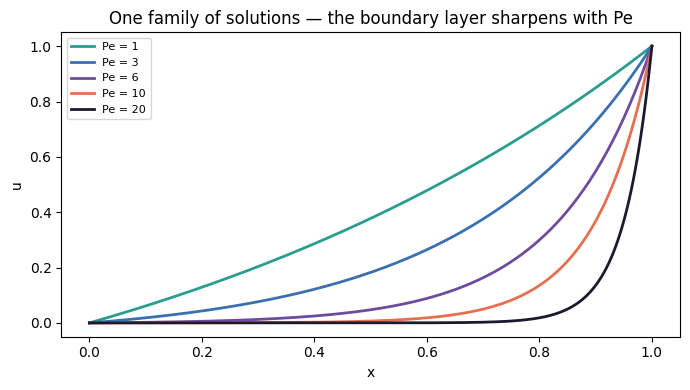

In [3]:
# what the family looks like: the boundary layer sharpening with Pe
xg = torch.linspace(0,1,300).reshape(-1,1)
plt.figure(figsize=(7,4))
for pe_val,c in zip([1,3,6,10,20], ["#2A9D8F","#3B6FB0","#6D4C9E","#E76F51","#1A1A2E"]):
    plt.plot(xg.numpy(), exact(xg, torch.full_like(xg,float(pe_val))).numpy(),
             color=c, lw=2, label=f"Pe = {pe_val}")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(fontsize=8)
plt.title("One family of solutions — the boundary layer sharpens with Pe")
plt.tight_layout()
plt.savefig("t9_parametric_pinn_family.png", dpi=300)
plt.show()

---

## 5 — Collocation in parameter space

This is the conceptual heart. In every earlier tutorial, collocation points lived in *space*. Here each point is a pair $(x, Pe)$ — a location **and** an operating condition. We scatter points through that two-dimensional space and enforce the residual at each, every point carrying its own Péclet number.

In [4]:
gen = torch.Generator().manual_seed(42)

x_f  = torch.rand(N_f,1,generator=gen).to(device).requires_grad_(True)
pe_f = (PE_LO + (PE_HI-PE_LO)*torch.rand(N_f,1,generator=gen)).to(device).requires_grad_(True)

print(f"collocation points in (x, Pe) space: {N_f}")
print(f"  x  spans [{x_f.min().item():.3f}, {x_f.max().item():.3f}]")
print(f"  Pe spans [{pe_f.min().item():.2f}, {pe_f.max().item():.2f}]")

collocation points in (x, Pe) space: 2000
  x  spans [0.002, 1.000]
  Pe spans [1.03, 19.98]


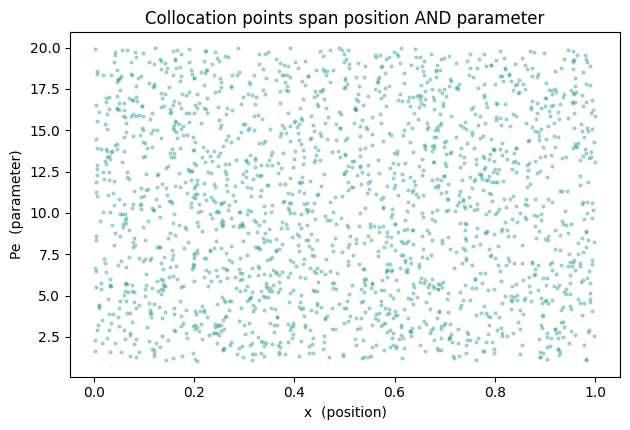

In [5]:
plt.figure(figsize=(6.4,4.4))
plt.scatter(x_f.detach().cpu(), pe_f.detach().cpu(), s=4, alpha=0.35, color="#2A9D8F")
plt.xlabel("x  (position)"); plt.ylabel("Pe  (parameter)")
plt.title("Collocation points span position AND parameter")
plt.tight_layout()
plt.savefig("t9_parametric_pinn_collocation.png", dpi=300)
plt.show()

---

## 6 — The network and hard boundary conditions

Two inputs now: $x$ and $Pe$. Both are normalised to $[-1,1]$ — essential here, since $Pe$ ranges up to 20 while $x$ stays in $[0,1]$, and unnormalised inputs of such different scales train badly.

The boundary conditions get the **hard-constraint** treatment from Tutorials 4 and 5:

$$u(x,Pe) = \underbrace{x}_{\text{lift}} + \underbrace{x(1-x)}_{\text{vanishes at both ends}}\,N(x,Pe)$$

At $x=0$ this gives $u=0$; at $x=1$ it gives $u=1$. Exactly, for **every** $Pe$, before any training — which matters more in a parametric setting, because soft BCs would otherwise have to be satisfied across the whole parameter range too.

In [6]:
class ParametricPINN(nn.Module):
    "Input (x, Pe) -> raw output N. The parameter is just another input."
    def __init__(self, n_hidden=64, n_layers=5):
        super().__init__()
        layers = [nn.Linear(2,n_hidden), nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden,1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, pe):
        xn = 2*x - 1                                     # x   in [0,1] -> [-1,1]
        pn = 2*(pe-PE_LO)/(PE_HI-PE_LO) - 1              # Pe  in range -> [-1,1]
        return self.net(torch.cat([xn,pn],dim=1))

model = ParametricPINN().to(device)

def solution(x, pe):
    "Hard BCs: u(0)=0 and u(1)=1 hold exactly for every Pe."
    return x + x*(1-x)*model(x,pe)

# verify the constraint across the parameter range, before training
for pe_val in [PE_LO, 10.0, PE_HI]:
    pe = torch.full((1,1), pe_val, device=device)
    u0 = solution(torch.zeros(1,1,device=device), pe).item()
    u1 = solution(torch.ones(1,1,device=device),  pe).item()
    print(f"  Pe={pe_val:5.1f}:  u(0)={u0:+.2e}  u(1)={u1:.6f}   (exact by construction)")
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters())}")

  Pe=  1.0:  u(0)=+0.00e+00  u(1)=1.000000   (exact by construction)
  Pe= 10.0:  u(0)=+0.00e+00  u(1)=1.000000   (exact by construction)
  Pe= 20.0:  u(0)=+0.00e+00  u(1)=1.000000   (exact by construction)

Trainable parameters: 16897


---

## 7 — The residual, with a per-point parameter

The residual is the usual one — except $Pe$ is no longer a constant in the code. It's a **tensor**, different at every collocation point, and it comes straight from the input:

$$r = \frac{du}{dx} - \frac{1}{Pe}\frac{d^2u}{dx^2}$$

Because the boundary conditions are hard-constrained, this residual is the **entire loss**. No boundary terms at all.

In [7]:
def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True)[0]

def residual(x, pe):
    "Convection-diffusion residual; pe varies point-to-point."
    u   = solution(x,pe)
    u_x = grad(u,x)
    u_xx = grad(u_x,x)
    return u_x - u_xx/pe            # <- the parameter enters the physics directly

def total_loss():
    return (residual(x_f,pe_f)**2).mean()

print(f"untrained loss: {total_loss().item():.3e}")

untrained loss: 9.396e-01


---

## 8 — Scoring across the whole range

A parametric surrogate needs parametric validation. We check the error at several Péclet numbers — including values the network never saw as exact training points.

In [8]:
def error_at(pe_val, n=200):
    "Relative L2 error against the exact solution at one Pe."
    x  = torch.linspace(0,1,n,device=device).reshape(-1,1)
    pe = torch.full_like(x, pe_val)
    with torch.no_grad(): up = solution(x,pe)
    ue = exact(x,pe)
    return (torch.linalg.norm(up-ue)/torch.linalg.norm(ue)).item()

TEST_PE = [1.0, 5.0, 10.0, 20.0]
print("untrained errors:", {p: f"{error_at(p):.2e}" for p in TEST_PE})

untrained errors: {1.0: '4.63e-02', 5.0: '9.47e-01', 10.0: '1.95e+00', 20.0: '3.45e+00'}


---

## 9 — Training: one run, the entire family

A single optimizer, a single loss. Every iteration samples the whole $(x,Pe)$ space at once, so the network learns all operating conditions simultaneously.

**Watch the four error columns fall together.** The high-$Pe$ column lags — that boundary layer is the hardest member of the family, and it's the honest cost of asking one network to cover everything.

**Reference run** (real values, CPU, seeds as set here):
```
[    0] loss=9.396e-01 | err@Pe=1:4.63e-02  @5:9.47e-01  @10:1.95e+00  @20:3.45e+00
[ 2000] loss=4.263e-04 | err@Pe=1:1.49e-03  @5:8.21e-04  @10:1.36e-02  @20:1.82e-02
[ 4000] loss=4.285e-05 | err@Pe=1:4.08e-03  @5:3.88e-03  @10:4.84e-03  @20:1.43e-02
[ 6000] loss=1.580e-04 | err@Pe=1:4.05e-03  @5:3.95e-03  @10:7.88e-03  @20:1.58e-02
```

In [9]:
history = {"it":[], "loss":[], **{f"e{p:g}":[] for p in TEST_PE}}
def record(it):
    l = total_loss().item()
    history["it"].append(it); history["loss"].append(l)
    errs = {p: error_at(p) for p in TEST_PE}
    for p in TEST_PE: history[f"e{p:g}"].append(errs[p])
    print(f"[{it:5d}] loss={l:.3e} | " +
          "  ".join(f"err@Pe={p:g}:{errs[p]:.2e}" for p in TEST_PE))

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
record(0)
t0=time.time()
for it in range(1, ITERS+1):
    optimizer.zero_grad(); total_loss().backward(); optimizer.step()
    if it % 1000 == 0: record(it)
print(f"\ntrained in {time.time()-t0:.1f}s — this single network now covers Pe in [{PE_LO},{PE_HI}]")

[    0] loss=9.396e-01 | err@Pe=1:4.63e-02  err@Pe=5:9.47e-01  err@Pe=10:1.95e+00  err@Pe=20:3.45e+00
[ 1000] loss=9.982e-04 | err@Pe=1:1.73e-02  err@Pe=5:1.60e-02  err@Pe=10:5.79e-03  err@Pe=20:9.21e-02
[ 2000] loss=9.300e-05 | err@Pe=1:5.06e-03  err@Pe=5:6.27e-03  err@Pe=10:4.54e-03  err@Pe=20:6.19e-03
[ 3000] loss=8.348e-05 | err@Pe=1:1.57e-03  err@Pe=5:5.16e-04  err@Pe=10:2.28e-03  err@Pe=20:1.21e-02
[ 4000] loss=1.498e-04 | err@Pe=1:6.21e-03  err@Pe=5:6.48e-03  err@Pe=10:7.61e-03  err@Pe=20:1.50e-02
[ 5000] loss=1.726e-04 | err@Pe=1:1.70e-03  err@Pe=5:4.27e-03  err@Pe=10:6.41e-03  err@Pe=20:9.15e-03
[ 6000] loss=1.446e-04 | err@Pe=1:2.40e-03  err@Pe=5:3.71e-03  err@Pe=10:5.89e-03  err@Pe=20:8.27e-03

trained in 211.0s — this single network now covers Pe in [1.0,20.0]


---

## 10 — The surrogate in action

The payoff. Query the trained network at **any** Péclet number, instantly, and compare against the exact solution — including at values that were never explicit training targets.

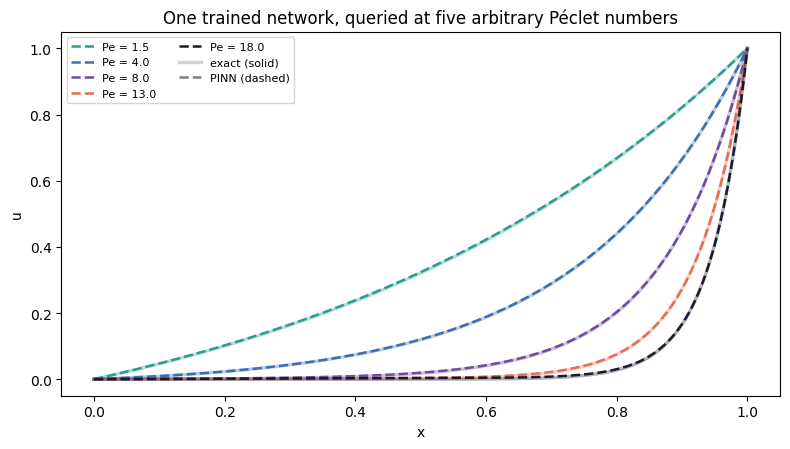

queried 100 operating points in 0.206s  (2.06 ms each)


In [10]:
x_plot = torch.linspace(0,1,300,device=device).reshape(-1,1)
query_pe = [1.5, 4.0, 8.0, 13.0, 18.0]        # arbitrary values, none of them "special"

plt.figure(figsize=(8,4.6))
for pe_val,c in zip(query_pe, ["#2A9D8F","#3B6FB0","#6D4C9E","#E76F51","#1A1A2E"]):
    pe = torch.full_like(x_plot, pe_val)
    with torch.no_grad(): up = solution(x_plot,pe)
    ue = exact(x_plot,pe)
    plt.plot(x_plot.cpu(), ue.cpu(), color=c, lw=2.4, alpha=0.35)
    plt.plot(x_plot.cpu(), up.cpu(), '--', color=c, lw=1.8, label=f"Pe = {pe_val}")
plt.plot([],[],color='gray',lw=2.4,alpha=0.35,label='exact (solid)')
plt.plot([],[],'--',color='gray',lw=1.8,label='PINN (dashed)')
plt.xlabel("x"); plt.ylabel("u"); plt.legend(fontsize=8, ncol=2)
plt.title("One trained network, queried at five arbitrary Péclet numbers")
plt.tight_layout()
plt.savefig("t9_parametric_pinn_query.png", dpi=300)
plt.show()

t0=time.time()
for pe_val in np.linspace(PE_LO,PE_HI,100):
    pe = torch.full_like(x_plot, float(pe_val))
    with torch.no_grad(): _ = solution(x_plot,pe)
print(f"queried 100 operating points in {time.time()-t0:.3f}s  "
      f"({(time.time()-t0)/100*1000:.2f} ms each)")

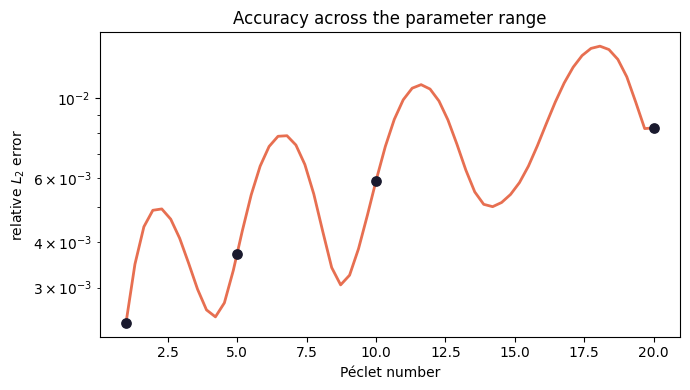

best  : 2.40e-03 at Pe=1.0
worst : 1.39e-02 at Pe=18.1


In [11]:
# error across the full range, including between training samples
pes = np.linspace(PE_LO, PE_HI, 60)
errs = [error_at(float(p)) for p in pes]
plt.figure(figsize=(7,4))
plt.semilogy(pes, errs, '-', color="#E76F51", lw=2)
plt.scatter(TEST_PE, [error_at(p) for p in TEST_PE], s=45, color="#1A1A2E", zorder=5)
plt.xlabel("Péclet number"); plt.ylabel("relative $L_2$ error")
plt.title("Accuracy across the parameter range")
plt.tight_layout()
plt.savefig("t9_parametric_pinn_error.png", dpi=300)
plt.show()
print(f"best  : {min(errs):.2e} at Pe={pes[int(np.argmin(errs))]:.1f}")
print(f"worst : {max(errs):.2e} at Pe={pes[int(np.argmax(errs))]:.1f}")

---

## 11 — Sensitivities for free

The second payoff, and the one that makes parametric PINNs genuinely useful for design.

Because $Pe$ is an *input*, $\partial u/\partial Pe$ is just another autograd call. This is the **sensitivity** of the solution to the parameter: which parts of the domain care most about the operating condition. Optimization needs it, uncertainty quantification needs it, and a mesh solver gets it only by finite-differencing repeated runs.

We validate against the exact analytic derivative:

$$\frac{\partial u}{\partial Pe}=\frac{x\,e^{Pe\,x}(e^{Pe}-1)-(e^{Pe\,x}-1)e^{Pe}}{(e^{Pe}-1)^2}$$

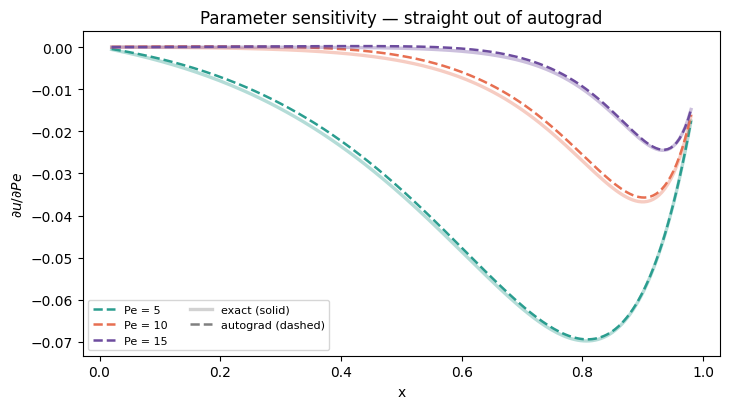

sensitivity at Pe=10, max abs difference: 1.514e-03


In [12]:
def sensitivity(x, pe_val):
    "du/dPe by autograd -- the parameter is an input, so this is one more grad call."
    pe = torch.full_like(x, pe_val).requires_grad_(True)
    u  = solution(x, pe)
    return torch.autograd.grad(u, pe, torch.ones_like(u))[0].detach()

def sensitivity_exact(x, p):
    e_px, e_p = torch.exp(p*x), math.exp(p)
    return (x*e_px*(e_p-1) - (e_px-1)*e_p)/(e_p-1)**2

x_s = torch.linspace(0.02,0.98,200,device=device).reshape(-1,1)
plt.figure(figsize=(7.4,4.2))
for pe_val,c in zip([5.0,10.0,15.0], ["#2A9D8F","#E76F51","#6D4C9E"]):
    s_pinn = sensitivity(x_s, pe_val)
    s_ex   = sensitivity_exact(x_s, pe_val)
    plt.plot(x_s.cpu(), s_ex.cpu(),  color=c, lw=2.4, alpha=0.35)
    plt.plot(x_s.cpu(), s_pinn.cpu(),'--', color=c, lw=1.8, label=f"Pe = {pe_val:g}")
plt.plot([],[],color='gray',lw=2.4,alpha=0.35,label='exact (solid)')
plt.plot([],[],'--',color='gray',lw=1.8,label='autograd (dashed)')
plt.xlabel("x"); plt.ylabel(r"$\partial u/\partial Pe$"); plt.legend(fontsize=8, ncol=2)
plt.title("Parameter sensitivity — straight out of autograd")
plt.tight_layout()
plt.savefig("t9_parametric_pinn_sensitivity.png", dpi=300)
plt.show()

s_p, s_e = sensitivity(x_s,10.0), sensitivity_exact(x_s,10.0)
print(f"sensitivity at Pe=10, max abs difference: {(s_p-s_e).abs().max().item():.3e}")

The sensitivity is near zero at the left of the domain and largest near the right wall — exactly where the boundary layer lives. That is the physical statement *"the operating condition matters most where the gradients are steep,"* delivered by a derivative that cost one line of code.

---

## 12 — Exercises

1. **Widen the range.** Push `PE_HI` to 50 or 100. Where does one network stop being able to cover the family? Does more capacity fix it, or is a range split the answer?
2. **Extrapolation test.** Query the trained surrogate at $Pe=30$ (outside training). Compare against exact. This is the most important cautionary experiment in the notebook.
3. **Sampling strategy.** Sample $Pe$ logarithmically instead of uniformly, concentrating points at the difficult high end. Does the error curve flatten?
4. **Two parameters.** Add a second parametric input — say a source strength — making the network $(x, Pe, q)\to u$. Watch the cost of covering a *plane* of the design space rather than a line.
5. **Optimization loop.** Use the surrogate inside an optimizer: find the $Pe$ that puts the steepest gradient at a target location. This is what surrogates are *for*, and the autograd sensitivity makes it gradient-based.
6. **Parametric flow.** Return to Tutorial 6's backward-facing step and make Reynolds number an input, training over $Re\in[100,300]$. Then plot reattachment length versus $Re$ as a **continuous curve** — from one training run.

---

## 13 — Failure modes to watch for

| Symptom | Cause | Fix |
|---|---|---|
| **Accurate at low parameter values, poor at high** | the hard end of the family (sharp boundary layer) is under-resolved | sample more points at high $Pe$; widen the network; train longer |
| Error blows up outside the trained range | networks **extrapolate badly** | never query outside `[PE_LO, PE_HI]` — retrain with a wider range instead |
| Training much slower than a single-$Pe$ run | expected — the domain gained a dimension | more collocation points and iterations; this is the cost of generality |
| Loss falls but errors stay flat | inputs not normalised — $Pe\sim20$ swamps $x\sim1$ | normalise both inputs to $[-1,1]$ |
| Sensitivities look like noise | the underlying solution isn't converged yet | fix the solution first; derivatives are always noisier than the field |
| Boundary conditions violated at some $Pe$ | soft BCs struggling across the range | use the hard constraint — it holds for every parameter by construction |

---

## 14 — Vocabulary

Only the terms this tutorial adds to the series:

- **Parametric PINN** — a network taking a physical parameter as an *input* alongside the spatial coordinates, so one model covers a whole family of problems.
- **Surrogate model** — a fast approximation queried in place of a full simulation; the object this tutorial produces.
- **Design space** — the range of operating conditions a surrogate spans; here the interval $Pe\in[1,20]$.
- **Parameter sensitivity** — $\partial u/\partial(\text{parameter})$, the derivative of the solution with respect to an operating condition; free from autograd when the parameter is an input.
- **Péclet number ($Pe$)** — the ratio of convective to diffusive transport; large $Pe$ pushes the solution into a thin boundary layer.
- **Boundary layer** — a thin region of steep gradient; the hardest member of this solution family and where the surrogate's error concentrates.
- **Interpolation vs. extrapolation** — querying inside the trained parameter range is reliable; outside it, networks fail badly and without warning.
- **Hard constraint** — building a boundary condition into the network output so it holds exactly for *every* parameter value, not just on average.
- **Amortisation** — paying a large one-off training cost so that each subsequent query is nearly free; the economic argument for surrogates.
- **Neural operator** — the structural alternative (DeepONet, FNO): learning a mapping between function spaces rather than a parameterised solution.


## 15 — What You Have Built (and Where the Series Goes)

You changed one thing — the parameter became an input — and the object you produced stopped being a solver and became a **surrogate**.

| | Conventional (Tutorials 1–8) | Parametric (this one) |
|---|---|---|
| network inputs | $x$ (and $t$) | $x$, **and the parameter** |
| covers | one operating point | an entire range |
| new operating point | retrain from scratch | **one forward pass** |
| sensitivity $\partial u/\partial\text{param}$ | finite-difference repeated runs, or an adjoint | **one autograd call** |
| cost | one solve per point | one longer training run, total |

**Why industry cares.** This is the shape of a *digital twin*. A model that answers "what happens at this operating condition?" in milliseconds, for any condition in its range, is something you can put inside an optimization loop, a control system, or a live dashboard. A conventional solver — however accurate — cannot be queried a thousand times a second.

**The honest trade.** A parametric network is asked to represent a whole family with the same weights that a dedicated network spends entirely on one member. So it is **harder to train** and **less accurate at any single point** than a focused solve. You saw exactly that in the error curve: fine at low $Pe$, degrading toward the sharp boundary layer at $Pe=20$. You buy generality with precision — and whether that's a good trade depends on whether you need one answer or a thousand.

**Where this series goes.** One tutorial remains, and it adds the last kind of coupling the series hasn't touched. Tutorials 1–7 coupled *equations*; Tutorial 8 coupled *data* to physics; this one coupled a whole *parameter range* into one model. **Tutorial 10** couples two **materials** — a solid cooled by a fluid, where the heat leaving one is exactly the heat entering the other, and neither side can be solved alone. It is the problem mechanical engineers simulate more than almost any other, it is awkward for mesh solvers, and it closes the series on a genuine PINN advantage: two networks, stitched by two loss terms.

---

### Get the Notebooks

The full series — all ten tutorials, with plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

### References

- Sun, L., Gao, H., Pan, S. & Wang, J.-X. (2020). *Surrogate modeling for fluid flows based on physics-constrained deep learning without simulation data.* CMAME **361**, 112732. — *parametric PINNs as surrogate models, the approach of this tutorial.*
- Lu, L. et al. (2021). *Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators.* Nature Machine Intelligence **3**, 218–229. — *the operator-learning alternative to parametric inputs.*
- Li, Z. et al. (2021). *Fourier neural operator for parametric partial differential equations.* ICLR. — *a different route to solution families, worth comparing against.*
- Patankar, S. V. (1980). *Numerical Heat Transfer and Fluid Flow.* Hemisphere. — *the convection–diffusion benchmark and its exact solution.*

*Next up: the finale — two materials, two networks, and an interface where neither side can be solved without the other. — Rohit Raj · HalfQubiX*